# Stage 1: VQ-VAE Motion Tokenizer — Bone Vector Representation

This notebook trains the VQ-VAE on the **bone vector** representation (parent-relative unit bone directions, see `src/fk.py` / `src/data/features.py`).

**Translation is no longer part of this model's job.** An earlier version included `root_xyz` in the feature (69->66 dims), but a real checkpoint showed translation reconstruction jittering 3.1x worse than the ground truth's own natural velocity -- traced to chunk-boundary discontinuity (each chunk is encoded/decoded independently, no cross-chunk continuity). Translation is now predicted by a separate small model (`notebooks/03_root_motion.ipynb`, `src/model/root_motion_net.py`) that runs on full, un-chunked sequences instead. This VQ-VAE now trains on **pure unit bone directions only** (`include_translation=False`), 63 dims instead of 66 -- purely a pose tokenizer. **Any earlier checkpoint of this model is stale** (trained on the old 66-dim feature) and needs retraining.

**Final configuration:**
- `src/model/vq.py`'s `VectorQuantizer` — literal original VQ-VAE (van den Oord et al. 2017): hard nearest-neighbor quantization, straight-through gradient estimator, codebook trained by gradient descent (`embed` is a plain `nn.Parameter`), **plus two additions, both explicitly requested and both confirmed necessary together**:
  1. **Sparsity loss** — the literal codebook-loss-only design only updates whichever code(s) win the argmin each batch, so codes that lose early sit frozen at random init forever. A differentiable softmin-over-distances proxy pushes gradient to reach more codes.
  2. **Data-driven codebook initialization** (`init_from_encoder_outputs`) — before training starts, run a batch of real data through the (untrained) encoder with no gradient, then initialize the codebook directly from those encoder outputs instead of random noise, so codes start on-distribution.
- **`sparsity_weight=0.1`** (lowered from `1.0`) — on a live training run, the sparsity term (an entropy proxy already close to its saturation point `-ln(num_codes)` once usage is well-spread) dominated the total loss magnitude relative to `l1`/`vel_l1`, likely dominating the gradient signal too even though it had little further to gain; lowering the weight lets reconstruction drive learning while the sparsity term still discourages collapse.
- **Body-only skeleton** (`body_only=True`) — drops the 30 finger joints, keeps the 22-joint body chain (`src/skeleton.py`'s `BODY_PARENTS`), for lower compute cost. Feature dim 66 instead of 156.
- **`num_codes=2048`** (reduced from `10000`) — the codebook-size scaling ablation (below) found 10k gave the best raw reconstruction/perplexity-per-code, but its sparsity ceiling is `-ln(10000)=-9.21`, which takes far more real training steps to approach than a smaller codebook's ceiling -- on CPU, for a real full-dataset run, `sparsity` was taking too long to reach an expected value at 10k. `2048`'s ceiling (`-ln(2048)=-7.62`) is reachable in meaningfully fewer steps, while still landing on a value the earlier ablation directly measured (2021/2048 active, 98.7%, perplexity 1558.6 at 200 seqs) rather than an untested size.
- **Encoder/decoder**: 1D CNN (`Conv1d`, feature channels as CNN channels, time as the spatial axis), GroupNorm after every conv layer.
- **Input**: deterministic, non-overlapping **64-frame chunks** per sequence (`[0:64], [64:128], [128:192], ...`, trailing remainder dropped) — not a random crop, not the padded full sequence. `chunk_len=64` in `MotionDataset`. Matches **T2M-GPT's** literal training crop length (T=64, downsample rate 4, codebook 512 -- [arxiv.org/abs/2301.06052](https://arxiv.org/abs/2301.06052)); we'd temporarily reduced this to 16 for finer detail, but reverted to the paper's value. A controlled small-scale comparison (300 seqs, 30 epochs, data-driven init fixed for both) confirmed deterministic chunking beats random cropping even with data-driven init applied to both: 98.6% active codes / 0.389 final train_l1 (deterministic) vs. 93.9% active / 0.419 (random crop).
- **Learning rate**: `1e-5` (every higher LR tested showed `l1` growing steadily given enough steps on real data).
- **Device**: CPU (explicit choice, not a default).

**Ablation 1 — init/sparsity, 52 joints, 512 codes** (200-sequence subset, 20 epochs, full-dataset aggregated usage):

| Configuration | Final l1 | Active codes | Perplexity |
|---|---|---|---|
| Random init + sparsity loss | 0.603 | 349/512 (68.2%) | 119.8 |
| Random init, no sparsity | 0.570 | 100/512 (19.5%) | 11.0 |
| Data-driven init, no sparsity | 0.498 | 318/512 (62.1%) | 51.8 |
| Data-driven init + sparsity loss | 0.512 | 511/512 (99.8%) | 398.6 |

**Ablation 2 — codebook size scaling, 22 joints (body-only), init+sparsity** (same recipe otherwise):

| num_codes | Data | Final l1 | Active codes | Perplexity | Perplexity/num_codes |
|---|---|---|---|---|---|
| 512 | 200 seqs | 0.512 | 511/512 (99.8%) | 398.6 | 77.9% |
| **2048** | 200 seqs | **~0.39-0.47** | **2021/2048 (98.7%)** | **1558.6** | **76.1%** |
| 10,000 | 500 seqs | ~0.31-0.39 | 9667/10000 (96.7%) | 8644.4 | 86.4% |

No ceiling found up to 10k codes — utilization stays high and the perplexity/num_codes ratio doesn't degrade, and 10k was the best raw reconstruction quality of any config tested. (That 10k row used more training sequences than the others, so it isn't a perfectly controlled comparison, but the trend across all three is consistent.) **Despite this, we're using `num_codes=2048` for the actual run** (see Final configuration above) -- the ablation measured best-case quality *given enough training*, but a real CPU run needs to actually finish converging in practice; `2048` is a middle ground that's both directly ablation-tested and reaches its sparsity ceiling much faster than `10000` would.

In [9]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
%matplotlib inline

from src.data.splits import load_splits
from src.data.normalize import NormStats
from src.data.dataset import MotionDataset
from src.model.vqvae import VQVAE
from src.train import train

## Data setup

In [10]:
ROOT = Path.cwd().parent
raw_dir = ROOT / "data/raw/motion_text_7000"

splits = load_splits(ROOT / "data/splits")
stats_bones = NormStats.load(ROOT / "data/stats/stats_bones_only_body.npz")

REPRESENTATION = "bones"
BODY_ONLY = True  # drop the 30 finger joints, keep the 22-joint body chain
INCLUDE_TRANSLATION = False  # translation is now predicted separately by the
                              # small root-motion net (notebooks/03_root_motion.ipynb),
                              # not by this VQ-VAE -- see intro cell.
FEATURE_DIM = 63  # 21 bones * 3 (unit directions only, no root_xyz)
CHUNK_LEN = 64  # deterministic, non-overlapping chunks per sequence:
                 # [0:64], [64:128], [128:192], ... -- not a random crop.
                 # Trailing frames that don't fill a full chunk are dropped.
                 # Matches T2M-GPT's literal training crop length (T=64,
                 # downsample rate 4, codebook 512) -- arxiv.org/abs/2301.06052.
                 # We'd temporarily reduced this to 16 for finer detail, but
                 # reverted to the paper's value.

train_ds = MotionDataset(
    splits["train"], raw_dir, REPRESENTATION, stats_bones,
    chunk_len=CHUNK_LEN, body_only=BODY_ONLY, include_translation=INCLUDE_TRANSLATION,
)
val_ds = MotionDataset(
    splits["val"], raw_dir, REPRESENTATION, stats_bones,
    chunk_len=CHUNK_LEN, body_only=BODY_ONLY, include_translation=INCLUDE_TRANSLATION,
)
test_ds = MotionDataset(
    splits["test"], raw_dir, REPRESENTATION, stats_bones,
    chunk_len=CHUNK_LEN, body_only=BODY_ONLY, include_translation=INCLUDE_TRANSLATION,
)

print(f"train: {len(train_ds)} chunks (chunk_len={CHUNK_LEN}, body_only={BODY_ONLY})")
print(f"val:   {len(val_ds)} chunks (chunk_len={CHUNK_LEN}, body_only={BODY_ONLY})")
print(f"test:  {len(test_ds)} chunks (chunk_len={CHUNK_LEN}, body_only={BODY_ONLY})")


train: 8673 chunks (chunk_len=64, body_only=True)
val:   461 chunks (chunk_len=64, body_only=True)
test:  481 chunks (chunk_len=64, body_only=True)


In [11]:
BATCH_SIZE = 32

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

batch = next(iter(train_loader))
print("batch shape:", batch.shape)  # (B, CHUNK_LEN, FEATURE_DIM)

batch shape: torch.Size([32, 64, 63])


## Model setup

In [12]:
device = torch.device("cpu")
print("device:", device)

model = VQVAE(
    feature_dim=FEATURE_DIM,
    code_dim=512,
    num_codes=2048,
    commitment_beta=0.25,
    sparsity_weight=0.1,
    sparsity_temperature=0.5,
    w_vel=0.5,
).to(device)

print("num params:", sum(p.numel() for p in model.parameters()))

device: cpu
num params: 17528383


## Data-driven codebook initialization

Run real data through the (untrained) encoder with no gradient, then initialize the codebook directly from those encoder outputs instead of random noise. Must happen before training starts.

In [13]:
model.eval()
all_z = []
with torch.no_grad():
    while sum(x.shape[0] for x in all_z) < model.vq.num_codes:
        for batch in train_loader:
            z = model.encoder(batch.to(device))
            all_z.append(z.reshape(-1, model.vq.code_dim))
            if sum(x.shape[0] for x in all_z) >= model.vq.num_codes:
                break
all_z = torch.cat(all_z, dim=0)
print(f"gathered {all_z.shape[0]} encoder outputs for codebook init")

model.vq.init_from_encoder_outputs(all_z)
model.train()
print("codebook initialized from data")

gathered 2048 encoder outputs for codebook init
codebook initialized from data


## Training loop

Your implementation goes here. `model(batch)` returns a dict with `recon`, `indices`, `usage`, `loss`, `loss_parts` (see `src/model/vqvae.py`).

Checkpoints should go to `checkpoints/vqvae_bones.pt`, logs to `reports/` (per the project layout), but structure it however works for you.

In [19]:
EPOCHS = 1
LR = 1e-5  # confirmed stable AND decreasing (0.82 -> 0.63 over 5 epochs on a
           # real-data check); every higher LR tested (2e-4, 5e-5, 3e-5)
           # showed l1 growing steadily on the full dataset given enough steps.
WARMUP_STEPS = 200

checkpoint_path = ROOT / "checkpoints/vqvae_bones.pt"
log_path = ROOT / "reports/vqvae_bones_log.csv"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

history = train(
    model,
    train_loader,
    val_loader,
    device,
    epochs=EPOCHS,
    lr=LR,
    warmup_steps=WARMUP_STEPS,
    log_path=log_path,
    checkpoint_path=checkpoint_path,
    log_every=1,
)

epoch    0 | train_l1=0.26730 val_l1=0.28376 train_total=0.28918 val_total=0.36476 sparsity=-0.57495 vel_l1=0.05083


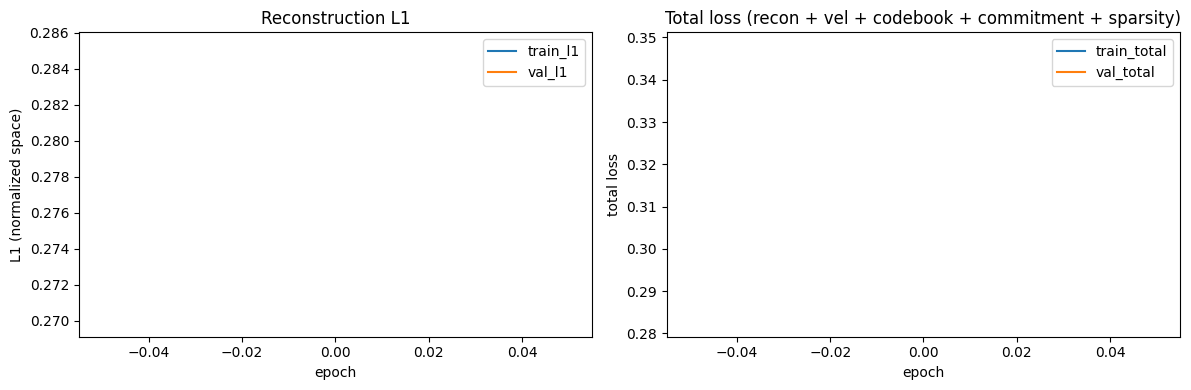

best val_l1: 0.28525


In [17]:
epochs_x = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_x, [h["train_l1"] for h in history], label="train_l1")
axes[0].plot(epochs_x, [h["val_l1"] for h in history], label="val_l1")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("L1 (normalized space)"); axes[0].legend(); axes[0].set_title("Reconstruction L1")

axes[1].plot(epochs_x, [h["train_total"] for h in history], label="train_total")
axes[1].plot(epochs_x, [h["val_total"] for h in history], label="val_total")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("total loss"); axes[1].legend(); axes[1].set_title("Total loss (recon + vel + codebook + commitment + sparsity)")
plt.tight_layout()
plt.show()

print(f"best val_l1: {min(h['val_l1'] for h in history):.5f}")

## Codebook health check

Quick sanity check that the codebook isn't collapsed (per the plan's Step 6b / verification item 7): active-code percentage and perplexity on a pass over the validation set, using the best checkpoint just saved.

In [20]:
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

usage_total = torch.zeros(model.vq.num_codes)
with torch.no_grad():
    for b in val_loader:
        b = b.to(device)
        out = model(b)
        usage_total += out["usage"].cpu()

active = (usage_total > 0).sum().item()
probs = usage_total[usage_total > 0] / usage_total.sum()
perplexity = torch.exp(-(probs * probs.log()).sum()).item()

print(f"active codes: {active}/{model.vq.num_codes} ({100*active/model.vq.num_codes:.1f}%)")
print(f"perplexity: {perplexity:.1f} (max possible: {model.vq.num_codes})")

active codes: 1461/2048 (71.3%)
perplexity: 1005.9 (max possible: 2048)


## Video rendering: qualitative reconstruction check

Pose comes from this VQ-VAE; translation comes from the separate root-motion net (`checkpoints/root_motion_net.pt`, trained in `03_root_motion.ipynb`). If that checkpoint doesn't exist yet, falls back to ground-truth translation so this cell still runs (with a printed warning) -- rendered pose quality is still meaningful, just not translation quality in that case.

In [21]:
from src.data.features import to_bones_feature, feature_to_joints
from src.fk import joints_to_bones
from src.model.root_motion_net import RootMotionNet
from src.data.root_motion import integrate_root_motion, _heading
from src.data.normalize import NormStats
from src.skeleton import BODY_PARENTS, NUM_BODY_JOINTS
from src.viz import render_comparison_video

stats_root_motion = NormStats.load(ROOT / "data/stats/stats_root_motion.npz")
root_motion_ckpt = ROOT / "checkpoints/root_motion_net.pt"
root_motion_net = None
if root_motion_ckpt.exists():
    root_motion_net = RootMotionNet(input_dim=FEATURE_DIM, hidden=64, out_dim=4)
    root_motion_net.load_state_dict(torch.load(root_motion_ckpt, map_location=device))
    root_motion_net.eval()
    print("using trained root-motion net for translation")
else:
    print("WARNING: no root-motion checkpoint found -- falling back to ground-truth "
          "translation (train notebooks/03_root_motion.ipynb to fix this)")


def render_reconstruction(sid: str, out_path: Path, fps: int = 20):
    joints = np.load(raw_dir / "joints" / f"{sid}.npy").astype(np.float32)
    joints = joints[:, :NUM_BODY_JOINTS, :]  # body-only
    T = joints.shape[0]
    n_chunks = T // CHUNK_LEN
    joints = joints[: n_chunks * CHUNK_LEN]

    # ground-truth per-frame bone lengths, used to invert the reconstructed
    # unit-vector directions back to real joint positions
    _, bone_vecs_gt = joints_to_bones(joints, parents=BODY_PARENTS, num_joints=NUM_BODY_JOINTS)
    bone_lengths_gt = np.linalg.norm(bone_vecs_gt, axis=-1)  # (T, 21)

    recon_chunks = []
    with torch.no_grad():
        for c in range(n_chunks):
            chunk = joints[c * CHUNK_LEN : (c + 1) * CHUNK_LEN]
            feat = to_bones_feature(chunk, body_only=True, include_translation=False)
            feat_norm = stats_bones.normalize(feat)
            x = torch.from_numpy(feat_norm.astype(np.float32)).unsqueeze(0).to(device)
            out = model(x)
            recon_feat = stats_bones.denormalize(out["recon"][0].cpu().numpy())
            recon_chunks.append(recon_feat)

    recon_unit_dirs_flat = np.concatenate(recon_chunks, axis=0)  # (T, 63), pose only

    if root_motion_net is not None:
        with torch.no_grad():
            x = torch.from_numpy(recon_unit_dirs_flat.astype(np.float32)).unsqueeze(0)
            pred_norm = root_motion_net(x)[0].numpy()
        pred_root_motion = stats_root_motion.denormalize(pred_norm)
        init_heading = _heading(joints[:1])[0]
        recon_root_xyz = integrate_root_motion(
            pred_root_motion, init_xz=tuple(joints[0, 0, [0, 2]]), init_heading=init_heading
        )
    else:
        recon_root_xyz = joints[:, 0, :]  # ground-truth fallback

    recon_joints = feature_to_joints(
        recon_unit_dirs_flat, "bones", bone_lengths=bone_lengths_gt, body_only=True,
        include_translation=False, root_xyz=recon_root_xyz,
    )

    render_comparison_video(joints, recon_joints, out_path, fps=fps, body_only=True)
    mpjpe_mm = np.linalg.norm(joints - recon_joints, axis=-1).mean() * 1000
    return mpjpe_mm

model.eval()
video_dir = ROOT / "reports/figures"
video_dir.mkdir(parents=True, exist_ok=True)

sample_ids = splits["test"][:3]
for sid in sample_ids:
    out_path = video_dir / f"recon_{sid}.mp4"
    mpjpe_mm = render_reconstruction(sid, out_path)
    print(f"{sid}: MPJPE={mpjpe_mm:.1f}mm -> {out_path}")


using trained root-motion net for translation
002591: MPJPE=761.0mm -> /Users/bereket/Desktop/Jupyter/metrina-vqvae/reports/figures/recon_002591.mp4
000972: MPJPE=448.4mm -> /Users/bereket/Desktop/Jupyter/metrina-vqvae/reports/figures/recon_000972.mp4
006482: MPJPE=77.2mm -> /Users/bereket/Desktop/Jupyter/metrina-vqvae/reports/figures/recon_006482.mp4
